# Missing CpG features: effect on clock performance

Investigates how CpG coverage affects each clock's ability to predict its own target. Two complementary analyses are run:

**Analysis 1 — Synthetic masking curve.** Starting from fully-observed (at inference) samples, additional CpGs are progressively masked and per-clock MAE / Pearson r / R² is recorded at each level. This is a controlled experiment: all variation comes from the masking, not sample differences.

**Analysis 2 — Real coverage bins.** Samples are grouped by their actual observed CpG fraction in the data and performance is computed within each bin. This shows what happens in practice when arrays have genuinely missing probes.

Both analyses score each clock only against its own true labels (not cross-clock).

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [3]:
from pathlib import Path
import numpy as np
import gc

# ── Which clocks to predict ──────────────────────────────────────
# None = "age" + every best_head_<clock>.pt found in HEAD_PATH.
# Or give a list, e.g. ["age", "horvath_age", "phenoage_age"]; "age" is always added first.
CLOCKS     = None

# ── Paths ────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_PATH     = ROOT / "data/03_final/combined_test/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"   # MethylGPT backbone + vocab + args.json
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks3_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261115_120827"
LORA_CKPT     = EPIHYDRA_PATH / "best_model.pt"           # LoRA backbone + the "age" head

# ── Model settings (must match training) ─────────────────────────
NUM_HEADS  = 4 # N clocks exlcuding "age" (chron age)

SPLIT_RATIOS = dict(train_ratio=None, valid_ratio=None, test_ratio=None)
BATCH_SIZE   = 16
RANDOM_STATE = 42

# ── Analysis 1: synthetic masking curve ───────────────────────────
# Fractions of CpGs to additionally mask on top of real missingness
MASK_FRACTIONS = np.round(np.arange(0.0, 1.0, 0.1), 2).tolist()

# ── Analysis 2: real coverage bins ────────────────────────────────
N_COVERAGE_BINS = 5    # number of equal-width bins from 0 % to 100 %
MIN_BIN_SAMPLES = 3    # bins with fewer samples are dropped

# ── Output ────────────────────────────────────────────────────────
SAVE_DIR = '/work/gr-fe/bryan/EpiHydra/results/figures/'        # Path to save figures, or None

## Imports

In [4]:
import json
import pickle
import warnings

# Silence noisy but harmless library warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import matplotlib.pyplot as plt
import torch
import pandas as pd

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
from evaluation import eval_utils as eu 
from epihydra import VocabWrapper, build_multiclock_dataloaders, evaluate
from clocks.epigenetic_clocks import (
    build_cpg_reference,     
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clock_names = eu.resolve_clocks(CLOCKS, HEAD_PATH)

print(f"Using device: {device}")
print(f"Evaluating clocks: '{clock_names}'")

Using device: cuda
Evaluating clocks: '['age', 'hannum_age', 'horvath_age', 'phenoage_age']'


## Load data, config and vocab

In [5]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
Saved training scalers are reused where available. Any clock without one (typically `"age"`) gets a fresh scaler fitted on this training split.

In [6]:
scalers = eu.load_scalers(HEAD_PATH, EPIHYDRA_PATH)

dataloader = build_multiclock_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_names  = clock_names,
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scalers      = scalers,   # reused where available, fitted otherwise
    mask_ratio   = 0,
    **SPLIT_RATIOS,
)

scalers = dataloader["scalers"]         # the scalers actually used, one per clock

Samples in meta : 1239
Samples in CpG  : 1239
Common samples  : 1239
Samples after drop : 1239
  age                 : 1239 labeled

Vocab CpGs : 49,159 | Present : 45,069 (91.7%) | Missing : 4,090
ℹ  age                 : reusing supplied pre-fitted scaler.
✓ Single multi-clock loader built (1239 samples, no masking).



/work/gr-fe/bryan/EpiHydra/epihydra/epihydra.py:125: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(X, axis=0)                  # (n_cpgs,) — NaN where all-NaN probe


## Build the multi-clock model
Frozen, LoRA-merged backbone + one trained head per clock.

In [7]:
mc_model  = eu.build_multiclock_model(MODEL_PATH, vocab, pretrain_config, device,
                                      ckpt=EPIHYDRA_PATH, head_path=HEAD_PATH,
                                      clock_names=clock_names)

I0000 00:00:1794837685.287144 1837539 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794837690.407056 1837539 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794837713.773324 1837539 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


LoRA from checkpoint: r=16, alpha=32


/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt

Loading frozen LoRA adapters from /work/gr-fe/bryan/EpiHydra/results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739/best_model.pt
  source run   : nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739
  source epoch : 28  (valid MAE 3.119)
  lora_r=16 lora_alpha=32 targets=['Wqkv', 'out_proj', 'linear1', 'linear2']
  adapter tensors in checkpoint : 52
  adapter tensors in model      : 52 (lora_A + lora_B pairs)
  lora_B with non-zero weights  : 26/26
  adapters merged into base weights

  loaded head age                  <- best_model.pt


## Baseline predictions (no extra masking)
Establish the unmasked performance on the chosen split before introducing synthetic missingness. The loader is rebuilt unshuffled so rows stay aligned to sample IDs.

In [11]:
loader = eu.ordered_loader(dataloader['loader'])
predictions  = eu.predict_multiclock(mc_model, loader, scalers, device, clock_names)

print(f"{len(predictions)} samples x {len(clock_names)} clocks")

1239 samples x 4 clocks


In [12]:
# Baseline per-clock metrics (pred vs. true for the same clock only)
baseline_rows = []
for name in clock_names:
    sub = predictions[[f"{name}_pred", f"{name}_true"]].dropna()
    p, t = sub.iloc[:, 0].to_numpy(), sub.iloc[:, 1].to_numpy()
    if len(p) < 2:
        continue
    from scipy.stats import pearsonr
    from sklearn.metrics import r2_score
    baseline_rows.append({
        "clock"    : name,
        "n"        : len(p),
        "mae"      : round(float(np.mean(np.abs(p - t))), 3),
        "pearson_r": round(float(pearsonr(p, t)[0]), 3),
        "r2"       : round(float(r2_score(t, p)), 3),
    })

baseline = pd.DataFrame(baseline_rows).set_index("clock")
print("Baseline performance (0 % extra masking)")
display(baseline)

Baseline performance (0 % extra masking)


,n,mae,pearson_r,r2
clock,,,,
age,1239,4.314,0.939,0.878
hannum_age,1239,2.865,0.975,0.943
horvath_age,1239,3.007,0.964,0.929
phenoage_age,1239,4.115,0.955,0.911


## Analysis 1 — Synthetic masking curve

For each masking fraction, the same random seed is used so comparisons across levels reflect the masking, not sample variation. The 0 % row should match the baseline above.

In [5]:
mask_results = pd.read_csv('/work/gr-fe/bryan/EpiHydra/results/mask_results.csv', index_col=0)

# mask_results = eu.evaluate_missing_fraction(mc_model, loader, scalers, device, clock_names,
#                                        MASK_FRACTIONS, seed=RANDOM_STATE, impute_ref=IMPUTE_REF)
# base = 1 - eu.compute_sample_coverage(dataloader["df"]).mean()
# mask_results["total_missing"] = base + mask_results["mask_frac"] * (1 - base)
#
# mask_results.to_csv('/work/gr-fe/bryan/EpiHydra/results/mask_results.csv')

print(mask_results.round(3).to_string(index=False))

       clock  mask_frac    n    mae  pearson_r     r2  total_missing
         age        0.0 1239  4.669      0.939  0.866          0.110
  hannum_age        0.0 1239  3.155      0.978  0.935          0.110
 horvath_age        0.0 1239  3.094      0.963  0.920          0.110
phenoage_age        0.0 1239  3.957      0.958  0.917          0.110
         age        0.1 1239  4.731      0.935  0.863          0.199
  hannum_age        0.1 1239  3.379      0.973  0.925          0.199
 horvath_age        0.1 1239  3.214      0.957  0.913          0.199
phenoage_age        0.1 1239  4.128      0.954  0.906          0.199
         age        0.2 1239  4.895      0.932  0.857          0.288
  hannum_age        0.2 1239  3.701      0.968  0.910          0.288
 horvath_age        0.2 1239  3.307      0.956  0.913          0.288
phenoage_age        0.2 1239  4.376      0.950  0.894          0.288
         age        0.3 1239  5.287      0.924  0.839          0.377
  hannum_age        0.3 1239  4.11

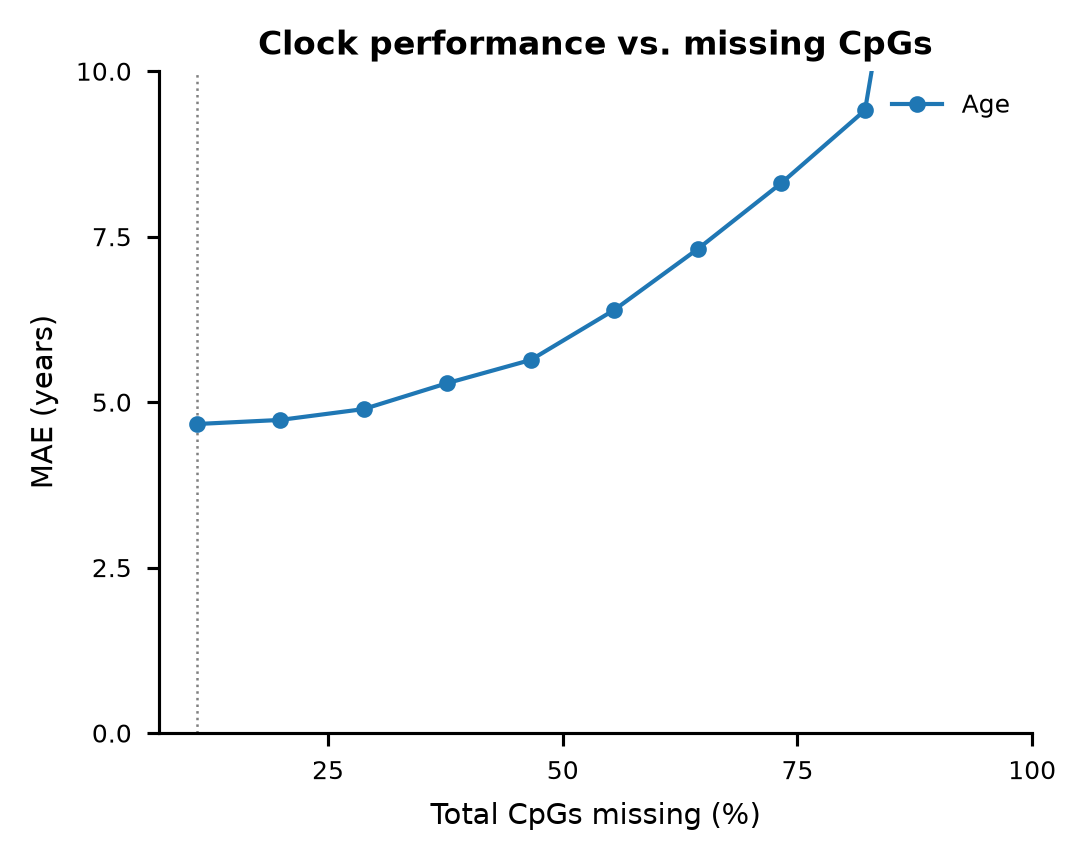

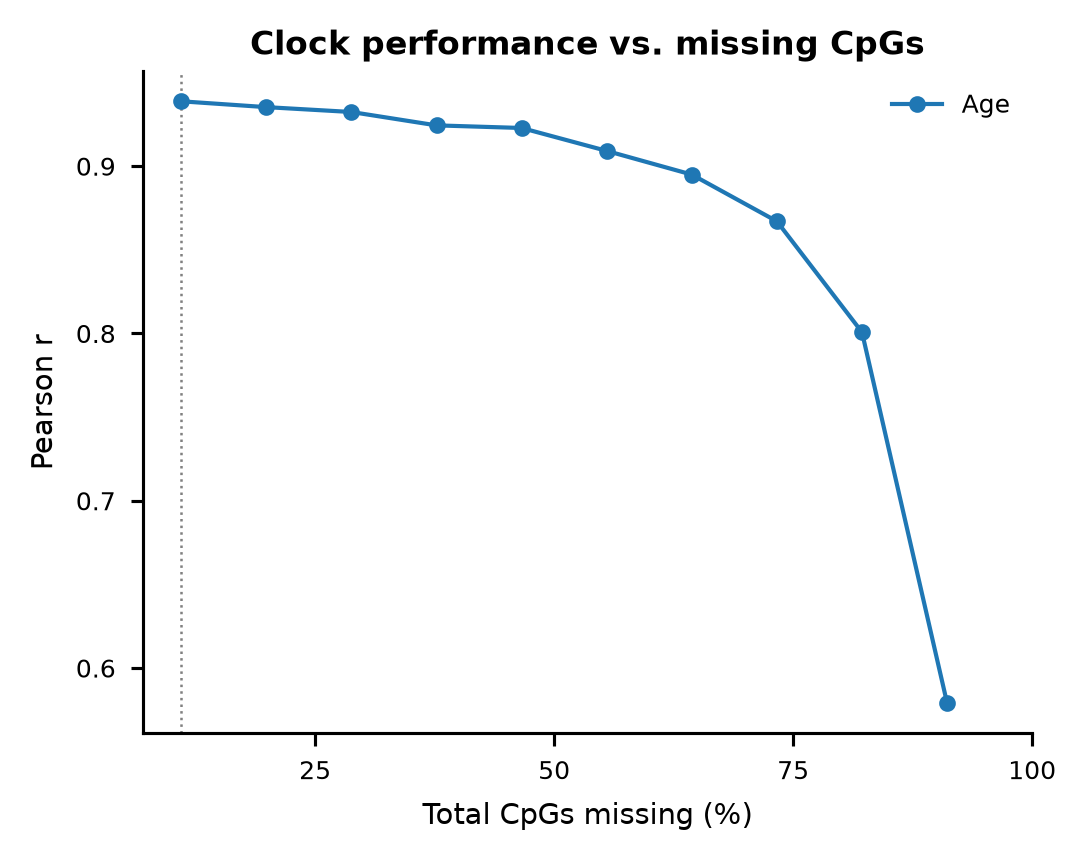

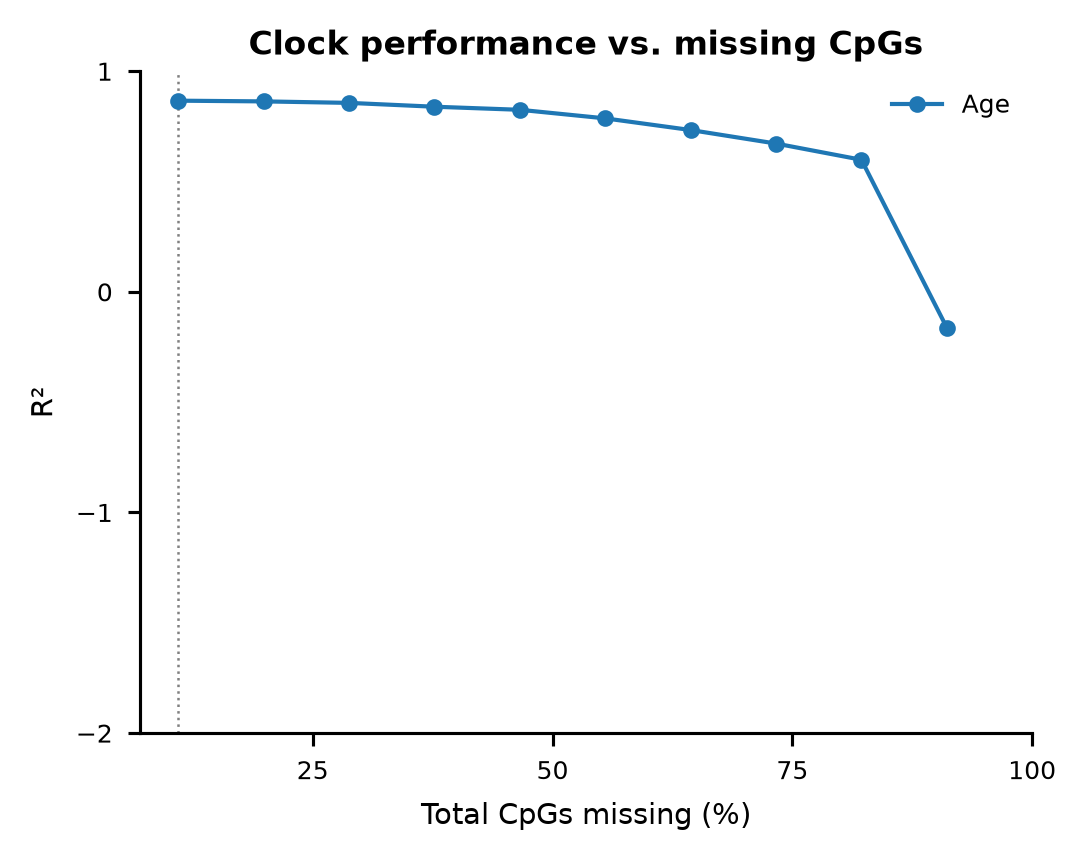

In [11]:
for metric in ("mae", "pearson_r", "r2"):
    fig, ax = eu.plot_missing_fraction_curves(mask_results, metric=metric, x='total_missing',
                                               clock_names=clock_names, )
    if metric == 'mae' : 
        ax.set_ylim(0 , 10)
    if metric == 'r2' : 
        ax.set_ylim(-2 , 1)
    if SAVE_DIR:
        fig.savefig(Path(SAVE_DIR) / f"masking_curve_{metric}.pdf")
        fig.savefig(Path(SAVE_DIR) / f"masking_curve_{metric}.png")

## Analysis 2 — Real CpG coverage bins

Each sample's coverage is the fraction of vocab CpGs that are non-NaN in the aligned data. Samples are binned by this fraction and per-clock performance is computed within each bin, using only samples that have a true label for that clock.

In [13]:
coverage_df = eu.compute_sample_coverage(dataloader["df"])

print("Coverage distribution:")
print(coverage_df.describe().round(3))

Coverage distribution:
count    1239.000
mean        0.890
std         0.009
min         0.880
25%         0.880
50%         0.899
75%         0.899
max         0.899
Name: cpg_coverage, dtype: float64


In [14]:
coverage_results = eu.coverage_performance(
    predictions, coverage_df, clock_names,
    n_bins      = N_COVERAGE_BINS,
    min_samples = MIN_BIN_SAMPLES,
)
display(coverage_results.round(3))

,clock,coverage_bin,coverage_mid,n,mae,pearson_r,r2
0,age,80%–100%,0.9,1239,4.667,0.939,0.867
1,hannum_age,80%–100%,0.9,1239,3.150,0.978,0.935
2,horvath_age,80%–100%,0.9,1239,3.093,0.963,0.920
3,phenoage_age,80%–100%,0.9,1239,3.956,0.958,0.917


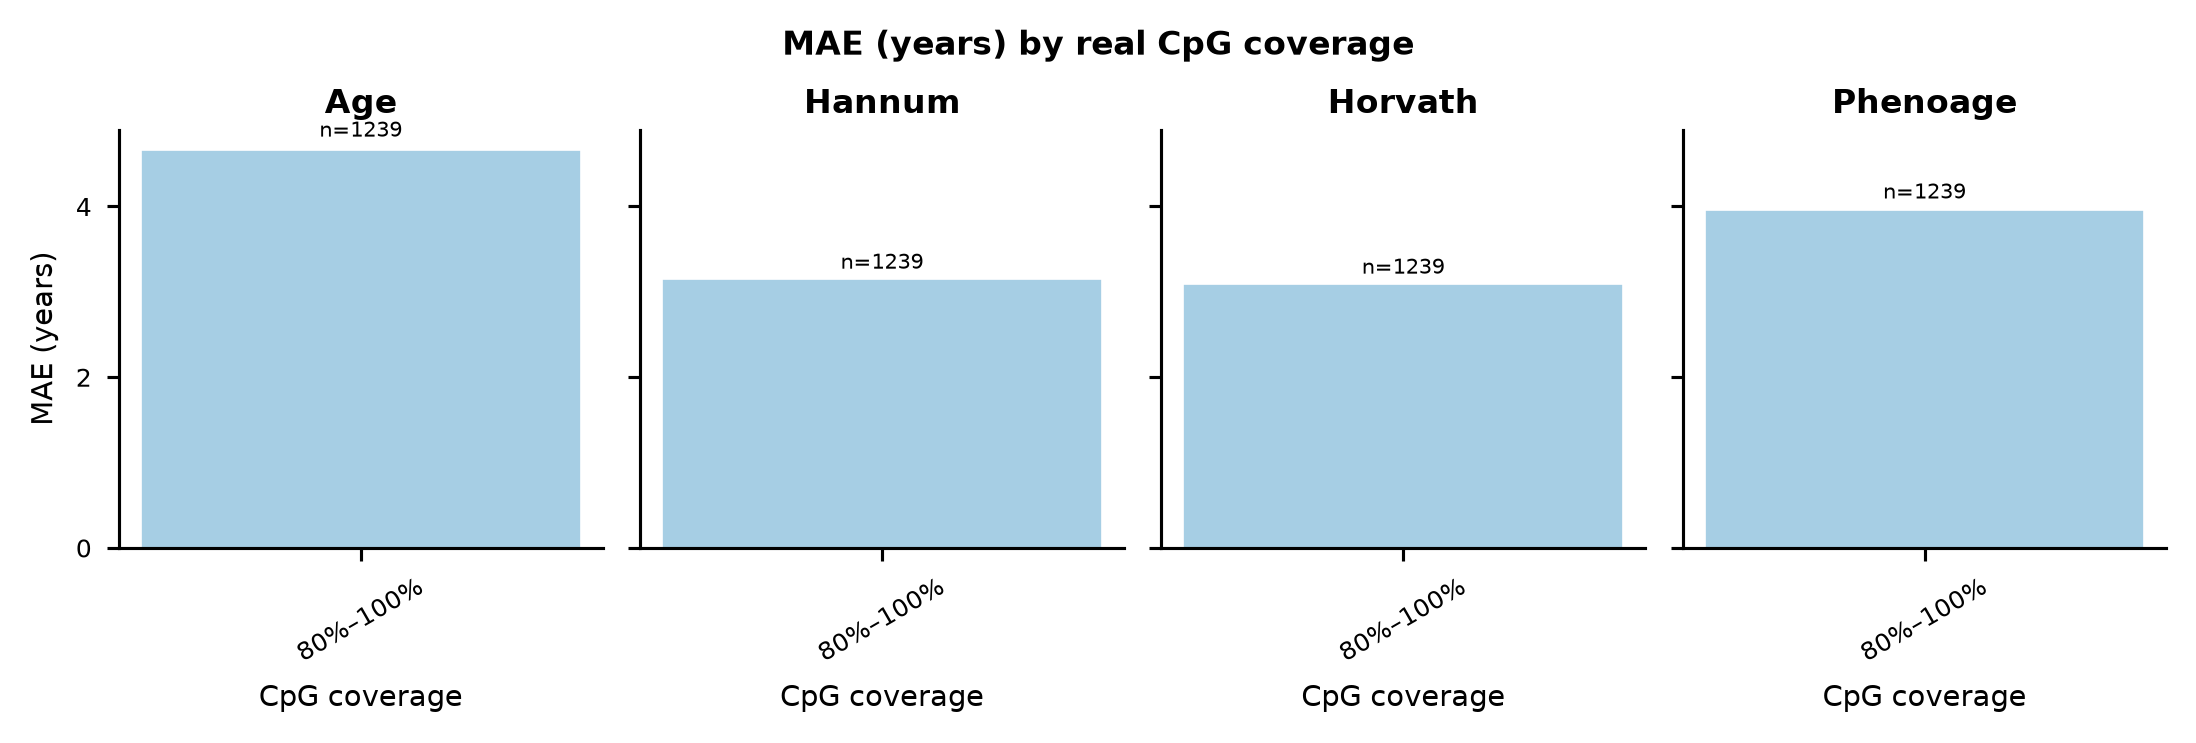

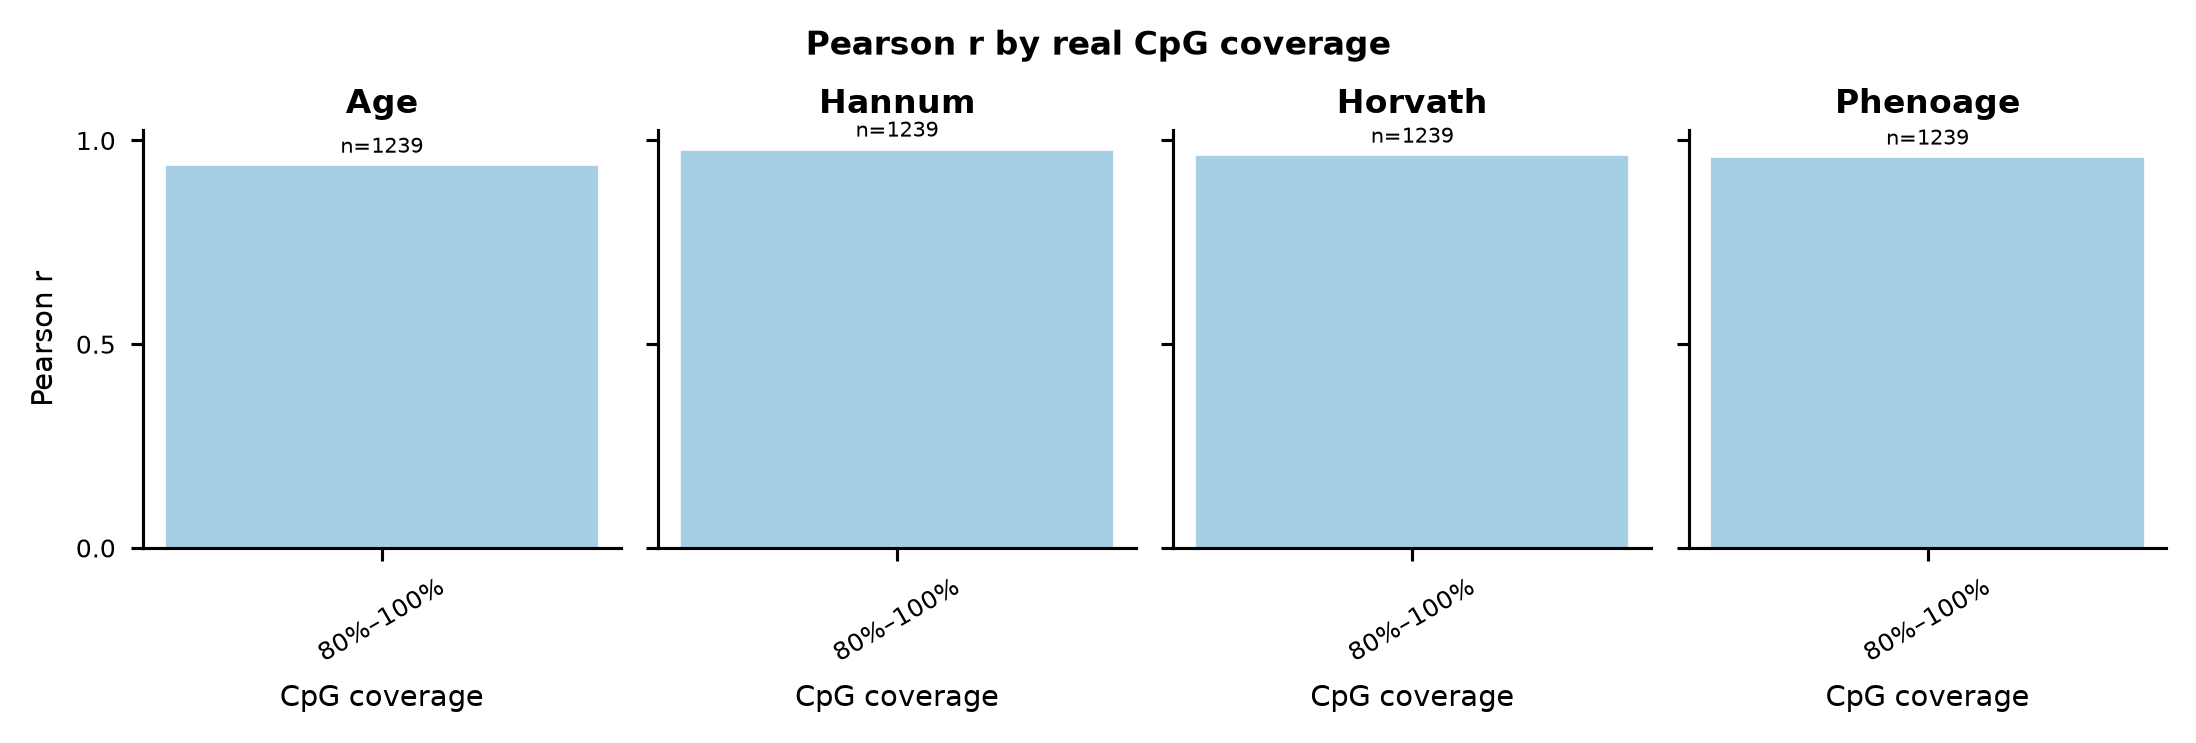

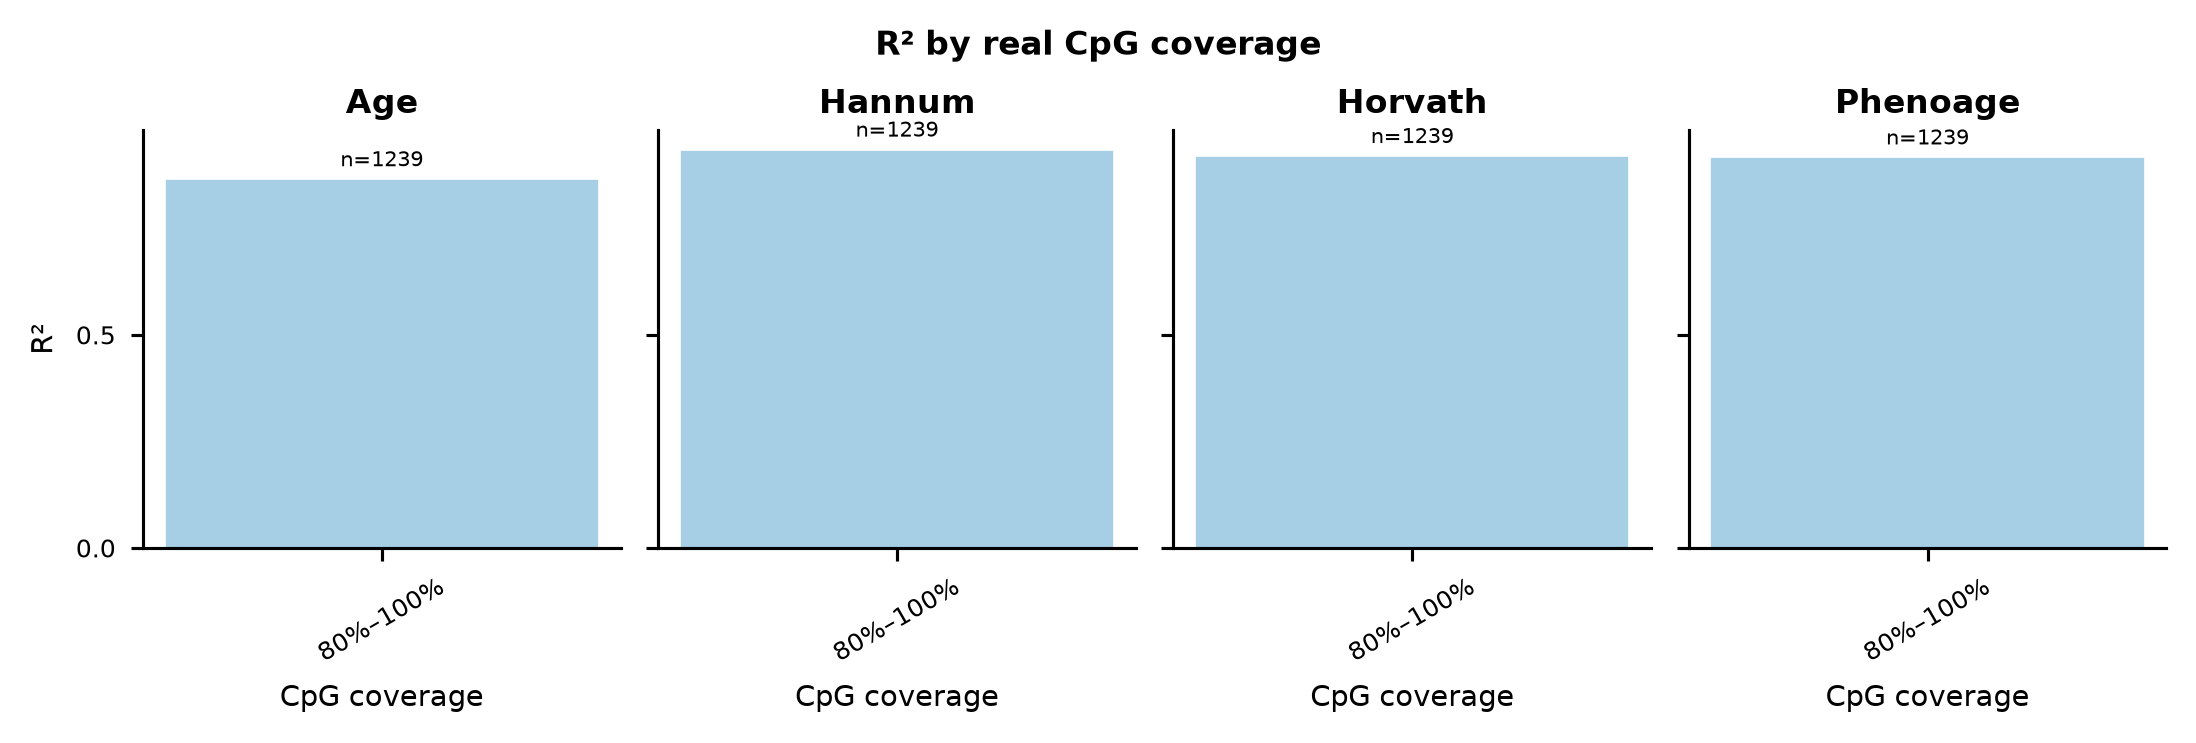

In [15]:
for metric in ("mae", "pearson_r", "r2"):
    fig, axes = eu.plot_coverage_performance(coverage_results, metric=metric,
                                              clock_names=clock_names)
    if SAVE_DIR:
        fig.savefig(Path(SAVE_DIR) / f"coverage_bins_{metric}.pdf")
        fig.savefig(Path(SAVE_DIR) / f"coverage_bins_{metric}.png")
    plt.show()

## Summary: baseline vs. high missingness

Compare baseline (0 % extra masking) to the most heavily masked level, so the cost of missingness is immediately visible.

In [16]:
worst_frac = max(MASK_FRACTIONS)
worst      = mask_results[mask_results["mask_frac"] == worst_frac].set_index("clock")

summary = baseline[["mae", "pearson_r", "r2"]].copy()
summary.columns = [f"baseline_{c}" for c in summary.columns]
for metric in ("mae", "pearson_r", "r2"):
    summary[f"masked_{metric}"] = worst[metric]
    delta = summary[f"masked_{metric}"] - summary[f"baseline_{metric}"]
    summary[f"delta_{metric}"] = delta.round(3)

display(summary.round(3))

,baseline_mae,baseline_pearson_r,baseline_r2,masked_mae,delta_mae,masked_pearson_r,delta_pearson_r,masked_r2,delta_r2
clock,,,,,,,,,
age,4.667,0.939,0.867,16.890,12.223,0.579,-0.360,-0.162,-1.029
hannum_age,3.150,0.978,0.935,46.091,42.941,0.376,-0.602,-8.801,-9.736
horvath_age,3.093,0.963,0.920,11.369,8.276,0.444,-0.519,0.168,-0.752
phenoage_age,3.956,0.958,0.917,51.145,47.189,0.443,-0.515,-8.031,-8.948
